# Five video creatives: a first look

Everything below is a SQL query against `creative_analytics.duckdb`, so any table or chart can be changed and re-run.

Two kinds of data are in here, and they should not be confused:

| Data | Where it comes from | Tables |
|---|---|---|
| Video metadata and a per-second timeline (scene cuts, motion, brightness, loudness) | Measured from the five videos | `raw.creatives`, `raw.creative_timeline` |
| Viewers, viewing sessions, biometrics, surveys | Simulated, with a fixed seed | `raw.viewers`, `raw.viewing_sessions`, `raw.biometric_events`, `raw.survey_responses` |

**The audience data is synthetic.** I don't have the real audience dataset, so I generated one to show how the model would be used. Sections 3 and 4 are therefore examples of the analysis, not findings about these creatives. Section 2 is the only part based on real data.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import pandas as pd

from creative_analytics.build_warehouse import ensure_warehouse

con = duckdb.connect(str(ensure_warehouse()), read_only=True)


def q(sql: str) -> pd.DataFrame:
    return con.sql(sql).df()


CREATIVES = {
    "norwich_you_are_not_alone": ("Norwich City", "#2a78d6"),
    "coordown_assume_that_i_can": ("CoorDown", "#eb6834"),
    "problem_with_attention": ("Problem with Attention", "#1baf7a"),
    "elf_peyton_lip_oil": ("e.l.f. @peytonxblack", "#eda100"),
    "elf_caro_lip_oil": ("e.l.f. @caro_manning", "#e87ba4"),
}
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": "#e1e0d9", "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 110,
})

## 1. The five creatives

Measured from the files. I labelled `brand` and `creative_category` by hand.

In [2]:
q('''
    SELECT creative_id, brand, creative_category, duration_seconds,
           width || 'x' || height AS resolution, fps, orientation
    FROM raw.creatives
    ORDER BY duration_seconds DESC
''')

,creative_id,brand,creative_category,duration_seconds,resolution,fps,orientation
0,norwich_you_are_not_alone,Norwich City,emotional_campaign,146.54,1280x720,25.0,landscape
1,coordown_assume_that_i_can,CoorDown,social_awareness,90.00,1280x720,25.0,landscape
2,problem_with_attention,Element Human,educational_content,69.13,1080x1920,24.0,vertical
3,elf_peyton_lip_oil,e.l.f. Cosmetics,ugc_product_ad,50.87,576x1024,30.0,vertical
4,elf_caro_lip_oil,e.l.f. Cosmetics,ugc_product_ad,32.80,576x1024,30.0,vertical


## 2. How each video is put together

`raw.creative_timeline` has one row per second of video, measured from the frames and the audio track.

In [3]:
q('''
    SELECT
        creative_id,
        count(*)                                            AS seconds,
        sum(is_scene_cut::INT)                              AS seconds_with_a_cut,
        round(sum(is_scene_cut::INT) * 60.0 / count(*), 1)  AS cuts_per_minute,
        round(avg(motion_score), 4)                         AS avg_motion,
        round(avg(audio_loudness_db), 1)                    AS avg_loudness_db
    FROM raw.creative_timeline
    GROUP BY creative_id
    ORDER BY cuts_per_minute DESC
''')

,creative_id,seconds,seconds_with_a_cut,cuts_per_minute,avg_motion,avg_loudness_db
0,coordown_assume_that_i_can,90,49.0,32.7,0.0108,-18.2
1,elf_peyton_lip_oil,51,15.0,17.6,0.0350,-26.7
2,elf_caro_lip_oil,33,6.0,10.9,0.0429,-22.7
3,norwich_you_are_not_alone,147,18.0,7.3,0.0191,-36.5
4,problem_with_attention,70,1.0,0.9,0.0045,-29.7


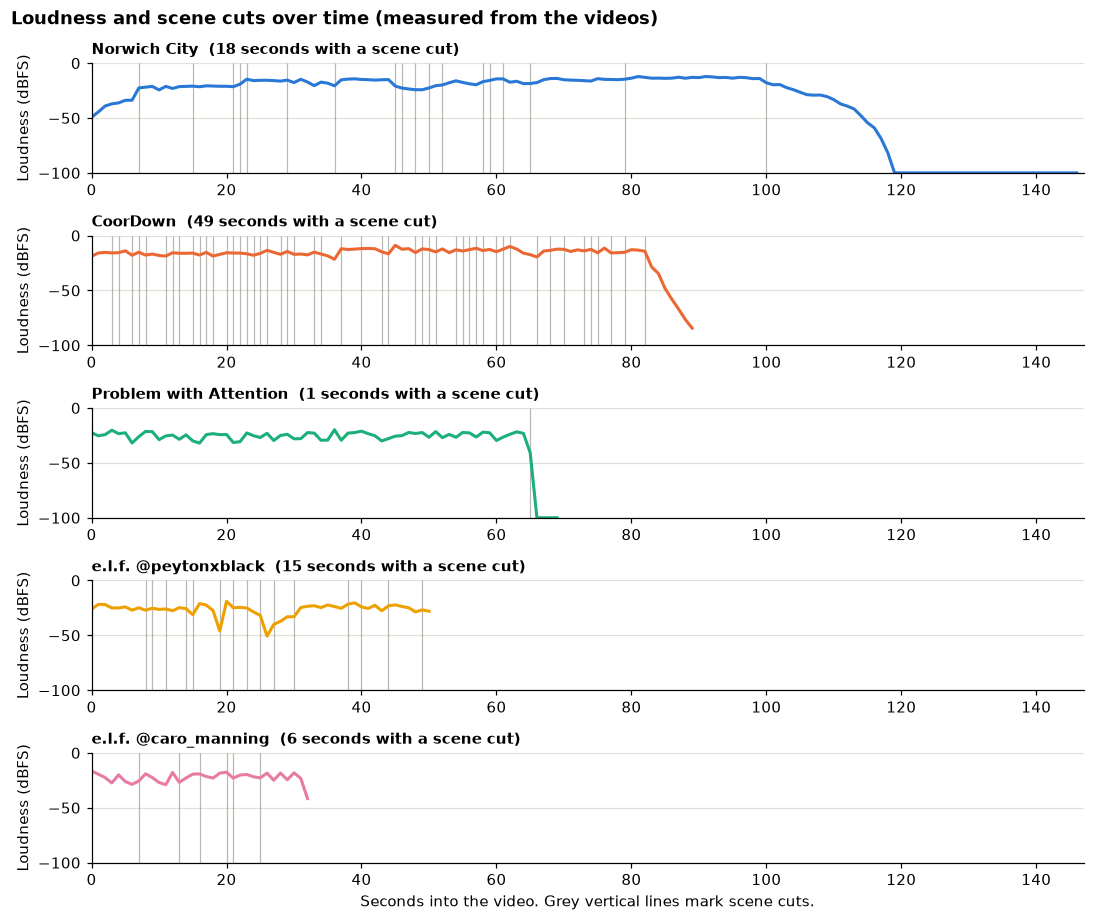

In [4]:
timeline = q("SELECT * FROM raw.creative_timeline ORDER BY creative_id, second")

fig, axes = plt.subplots(len(CREATIVES), 1, figsize=(10, 8.5), sharey=True)
for ax, (creative_id, (label, color)) in zip(axes, CREATIVES.items()):
    data = timeline[timeline["creative_id"] == creative_id]
    cuts = data.loc[data["is_scene_cut"], "second"]
    ax.vlines(cuts, -100, 0, color="#898781", linewidth=0.8, alpha=0.6)
    ax.plot(data["second"], data["audio_loudness_db"], color=color, linewidth=2)
    ax.set_title(f"{label}  ({len(cuts)} seconds with a scene cut)", fontsize=9.5)
    ax.set_xlim(0, timeline["second"].max() + 1)
    ax.set_ylim(-100, 0)
    ax.set_ylabel("Loudness (dBFS)")
axes[-1].set_xlabel("Seconds into the video. Grey vertical lines mark scene cuts.")
fig.suptitle("Loudness and scene cuts over time (measured from the videos)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

A few things stand out:

- CoorDown is by far the most heavily edited: there is a cut in 49 of its 90 seconds, roughly 33 a minute. It also has the loudest soundtrack.
- "The Problem with Attention" is basically one continuous shot. One cut in 69 seconds, almost no motion.
- Norwich City goes quiet at the end. The audio fades from about 100 seconds, the last 28 seconds are silent, and I found no cuts after the 100-second mark.
- The two e.l.f. videos are paced differently. @peytonxblack cuts about 18 times a minute over 51 seconds, @caro_manning about 11 times a minute over 33 seconds.

A caveat on the cut counts: the detector is a simple frame-difference rule. I checked it by eye against one of the e.l.f. videos and it picks up changes of location and framing but misses some jump cuts between similar shots, so the real numbers are probably a bit higher.

## 3. Attention through the video (synthetic)

The videos run from 33 to 147 seconds, so I plot attention against progress through the video (0-100%) instead of seconds.

One thing to keep in mind when reading the top chart: biometrics stop when a viewer leaves, so the later points only include people who kept watching. The bottom chart shows how many are left.

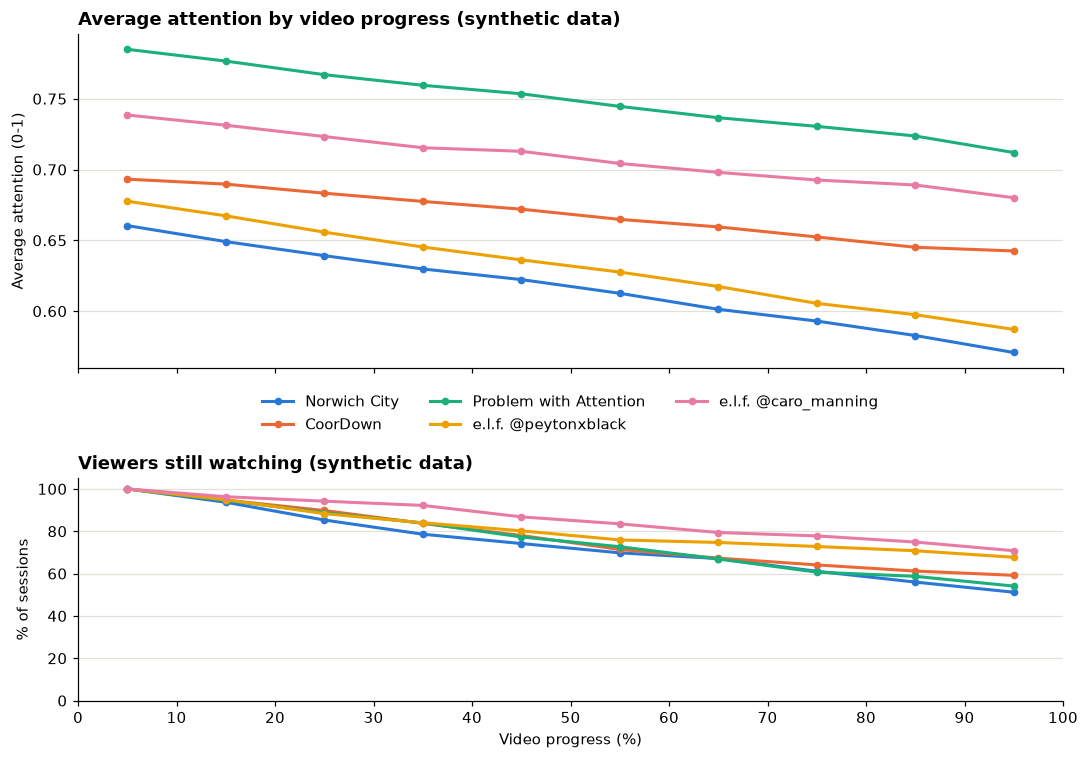

In [5]:
progress = q("SELECT * FROM analytics.attention_by_progress ORDER BY creative_id, progress_bin_start")

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, height_ratios=[3, 2])
for creative_id, (label, color) in CREATIVES.items():
    data = progress[progress["creative_id"] == creative_id]
    x = data["progress_bin_start"] + 5
    top.plot(x, data["avg_attention"], color=color, label=label, marker="o", markersize=4, linewidth=2)
    bottom.plot(x, data["pct_viewers_remaining"] * 100, color=color, marker="o", markersize=4, linewidth=2)
top.set_title("Average attention by video progress (synthetic data)")
top.set_ylabel("Average attention (0-1)")
top.legend(ncols=3, loc="upper center", bbox_to_anchor=(0.5, -0.04))
bottom.set_title("Viewers still watching (synthetic data)")
bottom.set_ylabel("% of sessions")
bottom.set_ylim(0, 105)
bottom.set_xlabel("Video progress (%)")
bottom.set_xticks(range(0, 101, 10))
fig.tight_layout()

## 4. The two e.l.f. videos side by side (synthetic)

Same product, two creators. `analytics.session_facts` has one row per session with the viewer, the biometric averages and the survey answers already joined, so this is a single query.

In [6]:
elf = q('''
    SELECT
        creative_id,
        count(*)                          AS n_sessions,
        round(avg(completed::INT), 2)     AS completion_rate,
        round(avg(avg_attention), 2)      AS avg_attention,
        round(avg(brand_recall::INT), 2)  AS brand_recall_rate,
        round(avg(likability), 2)         AS likability,
        round(avg(purchase_intent), 2)    AS purchase_intent
    FROM analytics.session_facts
    WHERE creative_id IN ('elf_peyton_lip_oil', 'elf_caro_lip_oil')
    GROUP BY creative_id
    ORDER BY creative_id DESC
''').set_index("creative_id")
elf

,n_sessions,completion_rate,avg_attention,brand_recall_rate,likability,purchase_intent
creative_id,,,,,,
elf_peyton_lip_oil,257,0.63,0.64,0.77,3.74,3.56
elf_caro_lip_oil,243,0.69,0.71,0.69,3.96,3.32


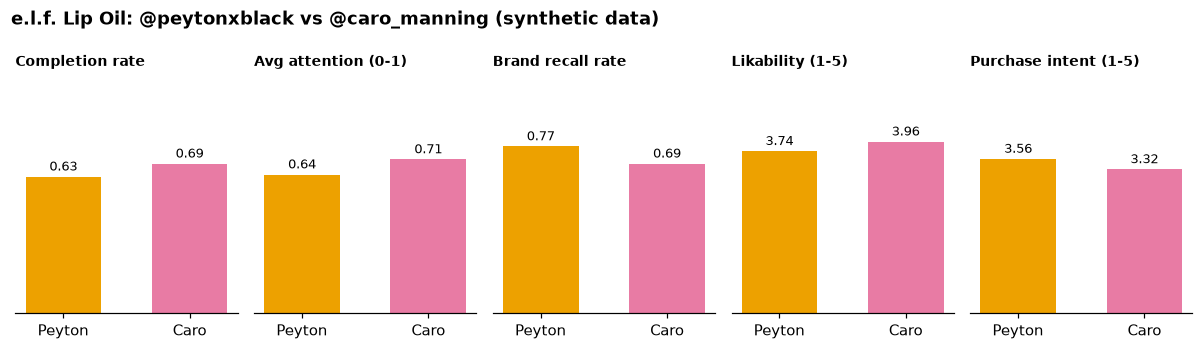

In [7]:
METRICS = {
    "completion_rate": ("Completion rate", 1.1),
    "avg_attention": ("Avg attention (0-1)", 1.1),
    "brand_recall_rate": ("Brand recall rate", 1.1),
    "likability": ("Likability (1-5)", 5.5),
    "purchase_intent": ("Purchase intent (1-5)", 5.5),
}
fig, axes = plt.subplots(1, len(METRICS), figsize=(11, 3.2))
for ax, (column, (title, top)) in zip(axes, METRICS.items()):
    bars = ax.bar(["Peyton", "Caro"], elf[column], color=[CREATIVES[c][1] for c in elf.index], width=0.6)
    ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=8.5)
    ax.set_title(title, fontsize=9)
    ax.set_ylim(0, top)
    ax.set_yticks([])
    ax.grid(False)
    ax.spines["left"].set_visible(False)
fig.suptitle("e.l.f. Lip Oil: @peytonxblack vs @caro_manning (synthetic data)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

In the simulated data neither creator simply wins. @caro_manning holds more attention and more people watch to the end, but @peytonxblack leaves more viewers remembering the brand and wanting to buy.

I set the numbers up that way on purpose. It is the situation "The Problem with Attention" describes: the creator who gets the attention is not necessarily the one who gets the brand remembered. With real data, this is the comparison I would want to run first.

## Try your own

Change the query below, or start from `sql/examples.sql`.

In [8]:
q('''
    SELECT creative_id, age_group, count(*) AS n_sessions, round(avg(avg_attention), 3) AS avg_attention
    FROM analytics.session_facts
    GROUP BY ALL
    ORDER BY creative_id, age_group
''').head(10)

,creative_id,age_group,n_sessions,avg_attention
0,coordown_assume_that_i_can,18-24,64,0.666
1,coordown_assume_that_i_can,25-34,54,0.676
2,coordown_assume_that_i_can,35-44,49,0.674
3,coordown_assume_that_i_can,45-54,47,0.680
4,coordown_assume_that_i_can,55+,31,0.685
5,elf_caro_lip_oil,18-24,60,0.717
6,elf_caro_lip_oil,25-34,62,0.711
7,elf_caro_lip_oil,35-44,52,0.715
8,elf_caro_lip_oil,45-54,47,0.719
9,elf_caro_lip_oil,55+,22,0.703
